In [1]:
import pandas as pd
columns = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

df = pd.read_csv("processed.cleveland.data", header=None, names=columns, na_values="?")


In [2]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
df.shape

(303, 14)

In [4]:
df. info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [5]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


### Intial Observations
There is a total of 303 rows and 14 columns. Ca has 299 values and thal has 301 values, but the total count is 303 so there may be missing values. Also the cholesterol has a high max value of 564, it could be a possible outlier but I will keep for now.

In [6]:
df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

In [7]:
print(df.duplicated().sum())

0


**Cleaning Log**

- I added the column names since the original file had no header.
- Found 4 missing values in ’ca’  and 2 in ‘thal’ 2. I kept these rows as those columns were not used in my analysis.  
- Age, cholesterol and heart  disease had no missing values.
- Kept cholesterol outliers because I had no evidence they were recording errors.
- Kept all 303 rows. 

In [8]:
df["num"].value_counts()

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

In [9]:
without_disease = df[df["num"] ==0]
with_disease = df[df["num"] >0]

In [10]:
without_disease["chol"].describe()

count    164.000000
mean     242.640244
std       53.456580
min      126.000000
25%      208.750000
50%      234.500000
75%      267.250000
max      564.000000
Name: chol, dtype: float64

In [11]:
with_disease["chol"].describe()

count    139.000000
mean     251.474820
std       49.486835
min      131.000000
25%      217.500000
50%      249.000000
75%      283.500000
max      409.000000
Name: chol, dtype: float64

In [12]:
with_disease["chol"].mean()- without_disease["chol"].mean()

np.float64(8.834576241445887)

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

In [14]:
df["Heart Disease"] = (df["num"] >0).replace({ False: "Without disease", True: "With disease"})

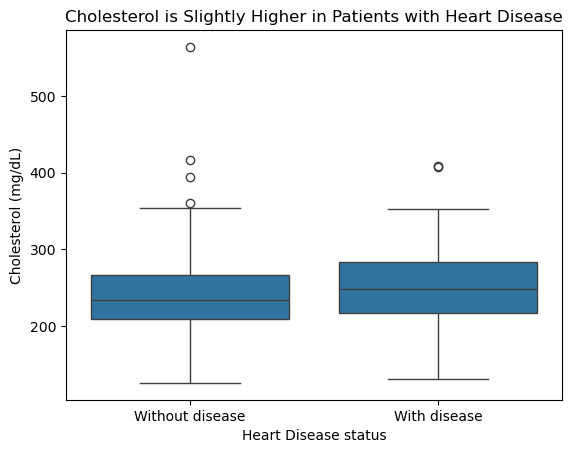

In [15]:
sns.boxplot(data=df, x ="Heart Disease",y = "chol")
plt.title("Cholesterol is Slightly Higher in Patients with Heart Disease")
plt.xlabel("Heart Disease status")
plt.ylabel("Cholesterol (mg/dL)")
plt.show()

**Observation:** Cholesterol is slightly higher in patients with Heart Disease. Also there is a few outliers in both groups.

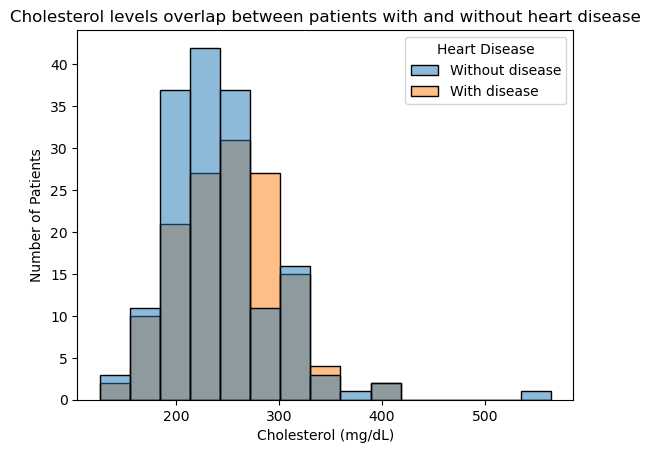

In [16]:
sns.histplot(data=df, x="chol", hue="Heart Disease", bins = 15)  
plt.title("Cholesterol levels overlap between patients with and without heart disease")
plt.xlabel("Cholesterol (mg/dL)")
plt.ylabel("Number of Patients")
plt.show()

**Observation:** Cholesterol levels overlap between patients with and without heart disease, with a few unsually high values.

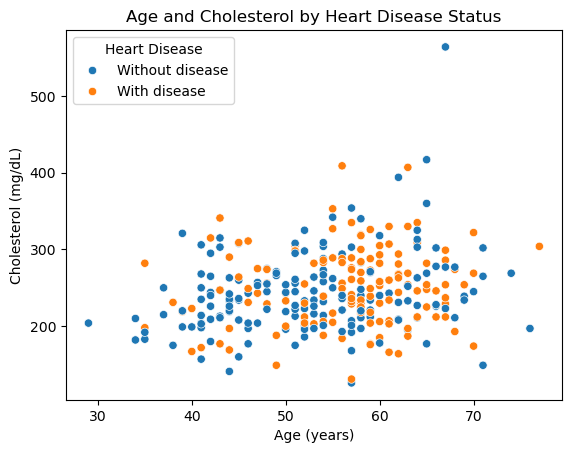

In [17]:
sns.scatterplot(data=df, x="age",y="chol", hue="Heart Disease")  
plt.title("Age and Cholesterol by Heart Disease Status")
plt.xlabel("Age (years)")
plt.ylabel("Cholesterol (mg/dL)")
plt.show()

**Observation**:Patients with and without heart disease have overlapping cholesterol levels across ages. There is no clear upward or downward pattern between age and cholesterol.

**Null Hypothesis**: There is no difference in the mean cholesterol levels for patients with heart disease and without.

In [18]:
from scipy.stats import ttest_ind
a = df[df["num"] >0]["chol"]
b = df[df["num"] ==0]["chol"]
ttest_ind(a, b)

TtestResult(statistic=np.float64(1.4829209163941466), pvalue=np.float64(0.13914167020436527), df=np.float64(301.0))

The t-value is 1.483 and p-value=0.139. Since p is greater than 0.05, this dataset doesn't provide enough evidence that  the groups mean cholesterol levels differ.

**Conclusion:**

My research question was "How does cholesterol levels differ between  patients with and without heart disease? The mean cholesterol was 251.47 mg/dL with disease versus 242.64 mg/dL without disease. The 8.83 mg/dL was not statistically significant with a p=0.139. The graphs show substantial overlap between the 2 groups. I decided to keep the outliers since I have no evidence that there was recording errors. Since this data only had 303 patients it may not represent the wider population to answer this question, which limits how the results can be applied.

https://github.com/jazzminowens/cs82a-portfolio